In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Spotify Genre Segmentation Project Started!")

Spotify Genre Segmentation Project Started!


In [3]:
print ("Pandas Version:",pd.__version__)
print("Numpy Version:",np.__version__)
print("All Libraries imported Successfully")

Pandas Version: 3.0.3
Numpy Version: 2.4.6
All Libraries imported Successfully


In [4]:
df=pd.read_csv("spotify_dataset.csv")
print("Dataset loaded successfully")
print("Number of rows and columns:",df.shape)
df.head()


Dataset loaded successfully
Number of rows and columns: (32833, 23)


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  str    
 1   track_name                32828 non-null  str    
 2   track_artist              32828 non-null  str    
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  str    
 5   track_album_name          32828 non-null  str    
 6   track_album_release_date  32833 non-null  str    
 7   playlist_name             32833 non-null  str    
 8   playlist_id               32833 non-null  str    
 9   playlist_genre            32833 non-null  str    
 10  playlist_subgenre         32833 non-null  str    
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-null  int64  
 14  loudness         

In [6]:
print("missing values in each column:")
print(df.isnull().sum())

missing values in each column:
track_id                    0
track_name                  5
track_artist                5
track_popularity            0
track_album_id              0
track_album_name            5
track_album_release_date    0
playlist_name               0
playlist_id                 0
playlist_genre              0
playlist_subgenre           0
danceability                0
energy                      0
key                         0
loudness                    0
mode                        0
speechiness                 0
acousticness                0
instrumentalness            0
liveness                    0
valence                     0
tempo                       0
duration_ms                 0
dtype: int64


In [7]:
df.describe()

,track_popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
count,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000
mean,42.477081,0.654850,0.698619,5.374471,-6.719499,0.565711,0.107068,0.175334,0.084747,0.190176,0.510561,120.881132,225799.811622
std,24.984074,0.145085,0.180910,3.611657,2.988436,0.495671,0.101314,0.219633,0.224230,0.154317,0.233146,26.903624,59834.006182
min,0.000000,0.000000,0.000175,0.000000,-46.448000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4000.000000
25%,24.000000,0.563000,0.581000,2.000000,-8.171000,0.000000,0.041000,0.015100,0.000000,0.092700,0.331000,99.960000,187819.000000
50%,45.000000,0.672000,0.721000,6.000000,-6.166000,1.000000,0.062500,0.080400,0.000016,0.127000,0.512000,121.984000,216000.000000
75%,62.000000,0.761000,0.840000,9.000000,-4.645000,1.000000,0.132000,0.255000,0.004830,0.248000,0.693000,133.918000,253585.000000
max,100.000000,0.983000,1.000000,11.000000,1.275000,1.000000,0.918000,0.994000,0.994000,0.996000,0.991000,239.440000,517810.000000


In [8]:
print("Duplicate Records:",df.duplicated().sum())

Duplicate Records: 0


In [10]:
df = df.drop_duplicates()
print("After Removing Duplicates:")
print("Dataset Shape:",df.shape)

After Removing Duplicates:
Dataset Shape: (32833, 23)


In [13]:
print ("Total Columns:",len(df.columns))
for col in df.columns:
    print(col)

Total Columns: 23
track_id
track_name
track_artist
track_popularity
track_album_id
track_album_name
track_album_release_date
playlist_name
playlist_id
playlist_genre
playlist_subgenre
danceability
energy
key
loudness
mode
speechiness
acousticness
instrumentalness
liveness
valence
tempo
duration_ms


In [14]:
features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo',
    'duration_ms'
]
X = df[features].copy()

print("Selected Features:")
print(X.head())

print("\nFeature Dataset Shape:", X.shape)

Selected Features:
   danceability  energy  loudness  speechiness  acousticness  \
0         0.748   0.916    -2.634       0.0583        0.1020   
1         0.726   0.815    -4.969       0.0373        0.0724   
2         0.675   0.931    -3.432       0.0742        0.0794   
3         0.718   0.930    -3.778       0.1020        0.0287   
4         0.650   0.833    -4.672       0.0359        0.0803   

   instrumentalness  liveness  valence    tempo  duration_ms  
0          0.000000    0.0653    0.518  122.036       194754  
1          0.004210    0.3570    0.693   99.972       162600  
2          0.000023    0.1100    0.613  124.008       176616  
3          0.000009    0.2040    0.277  121.956       169093  
4          0.000000    0.0833    0.725  123.976       189052  

Feature Dataset Shape: (32833, 10)


In [15]:
print("Missing Values:")
print(X.isnull().sum())

print("\nTotal Missing Values:", X.isnull().sum().sum())

Missing Values:
danceability        0
energy              0
loudness            0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
duration_ms         0
dtype: int64

Total Missing Values: 0


In [16]:
X = X.fillna(X.median())

print("Missing Values Handled Successfully!")
print("Remaining Missing Values:", X.isnull().sum().sum())

Missing Values Handled Successfully!
Remaining Missing Values: 0


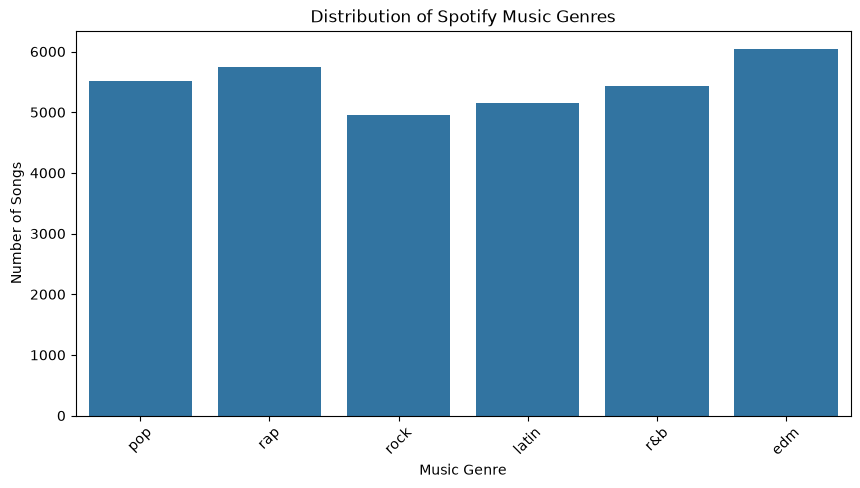

In [17]:
plt.figure(figsize=(10,5))

sns.countplot(data=df, x='playlist_genre')

plt.title("Distribution of Spotify Music Genres")
plt.xlabel("Music Genre")
plt.ylabel("Number of Songs")
plt.xticks(rotation=45)

plt.show()

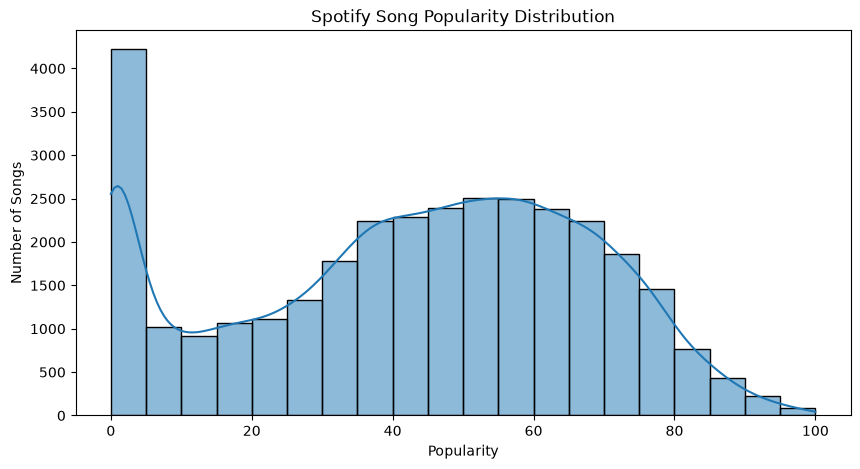

In [18]:
plt.figure(figsize=(10,5))

sns.histplot(df['track_popularity'], bins=20, kde=True)

plt.title("Spotify Song Popularity Distribution")
plt.xlabel("Popularity")
plt.ylabel("Number of Songs")

plt.show()

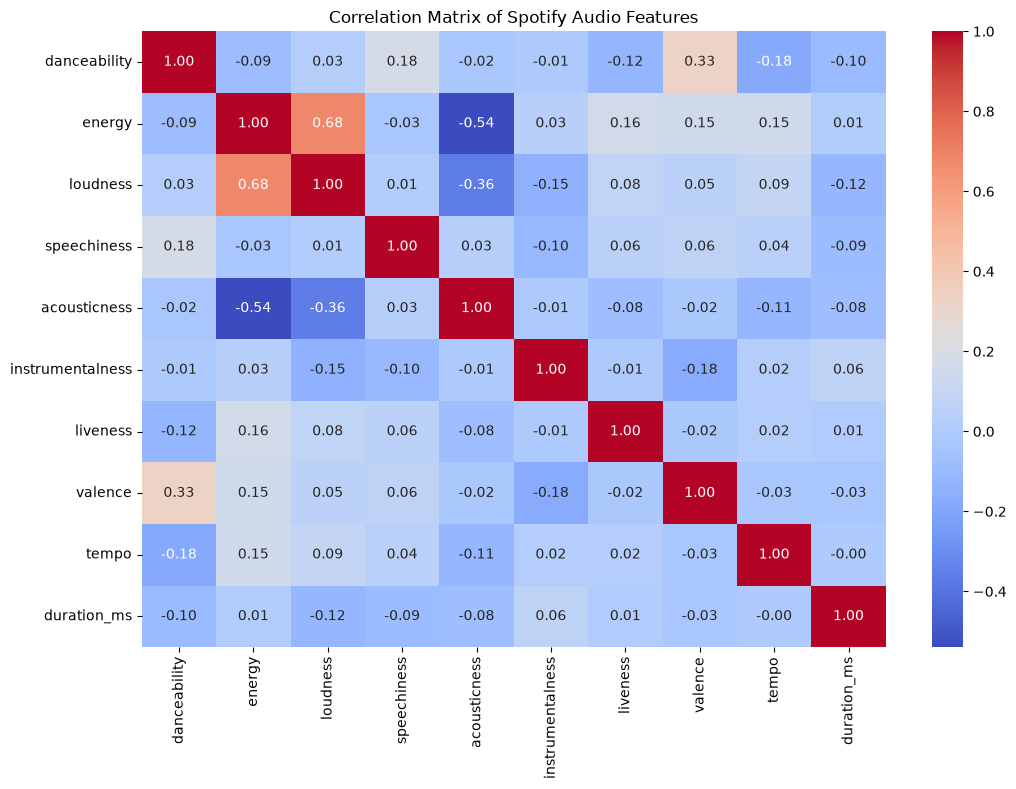

In [19]:
plt.figure(figsize=(12,8))

correlation = X.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Matrix of Spotify Audio Features")
plt.show()

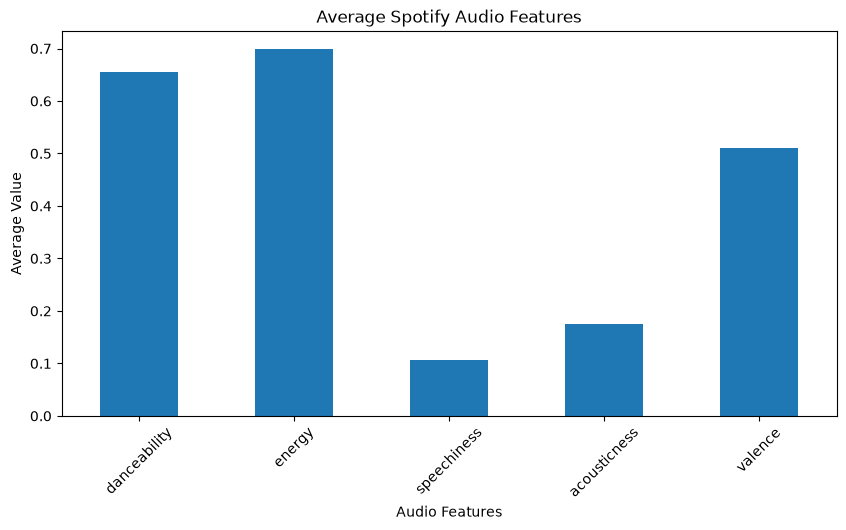

In [20]:
audio_features = [
    'danceability',
    'energy',
    'speechiness',
    'acousticness',
    'valence'
]

X[audio_features].mean().plot(
    kind='bar',
    figsize=(10,5)
)

plt.title("Average Spotify Audio Features")
plt.xlabel("Audio Features")
plt.ylabel("Average Value")
plt.xticks(rotation=45)

plt.show()

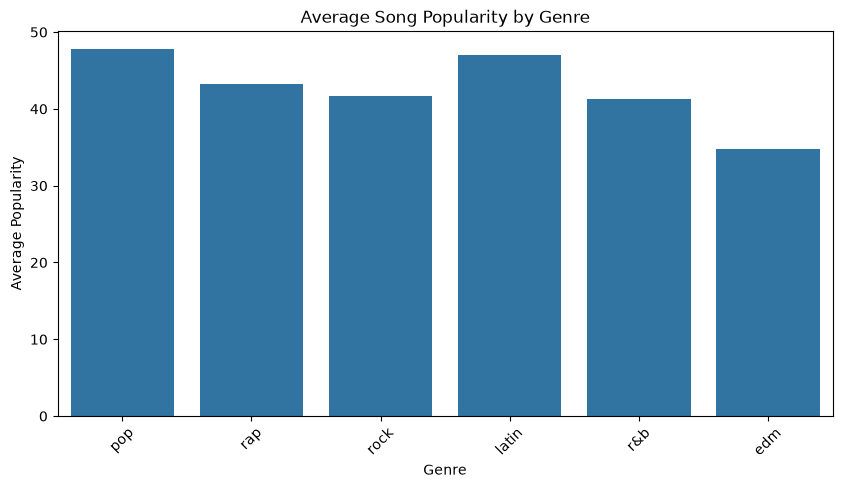

In [21]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=df,
    x='playlist_genre',
    y='track_popularity',
    errorbar=None
)

plt.title("Average Song Popularity by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Popularity")
plt.xticks(rotation=45)

plt.show()

In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature Scaling Completed!")
print("Scaled Dataset Shape:", X_scaled.shape)

Feature Scaling Completed!
Scaled Dataset Shape: (32833, 10)


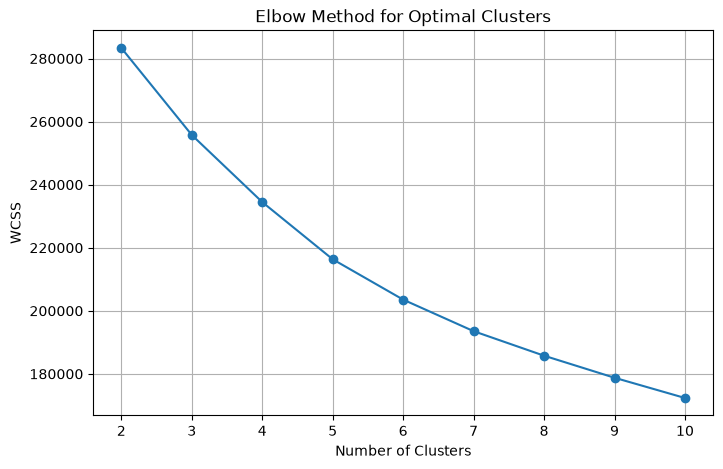

In [23]:
from sklearn.cluster import KMeans

wcss = []

for i in range(2, 11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(2, 11), wcss, marker='o')

plt.title("Elbow Method for Optimal Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.grid()
plt.show()

In [24]:
kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means Model Trained Successfully!")
print("\nCluster Distribution:")
print(df['Cluster'].value_counts().sort_index())

K-Means Model Trained Successfully!

Cluster Distribution:
Cluster
0     8466
1     2470
2     2128
3    10762
4     4327
5     4680
Name: count, dtype: int64


In [25]:
df[['track_name', 'track_artist',
    'playlist_genre', 'Cluster']].head(10)

,track_name,track_artist,playlist_genre,Cluster
0,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,pop,3
1,Memories - Dillon Francis Remix,Maroon 5,pop,3
2,All the Time - Don Diablo Remix,Zara Larsson,pop,3
3,Call You Mine - Keanu Silva Remix,The Chainsmokers,pop,0
4,Someone You Loved - Future Humans Remix,Lewis Capaldi,pop,3
5,Beautiful People (feat. Khalid) - Jack Wins Remix,Ed Sheeran,pop,3
6,Never Really Over - R3HAB Remix,Katy Perry,pop,0
7,Post Malone (feat. RANI) - GATTÜSO Remix,Sam Feldt,pop,0
8,Tough Love - Tiësto Remix / Radio Edit,Avicii,pop,2
9,If I Can't Have You - Gryffin Remix,Shawn Mendes,pop,0


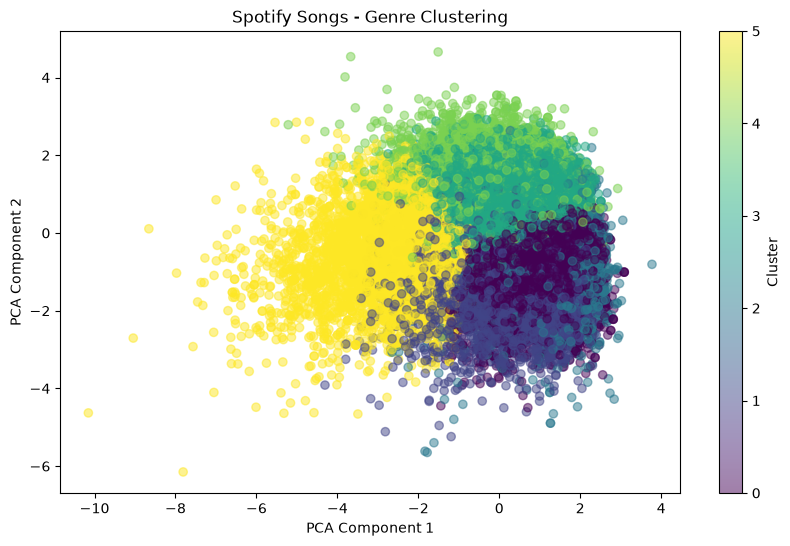

In [26]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df['Cluster'],
    cmap='viridis',
    alpha=0.5
)

plt.title("Spotify Songs - Genre Clustering")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(label="Cluster")
plt.show()

Genre-wise Cluster Analysis:


Cluster,0,1,2,3,4,5
playlist_genre,,,,,,
edm,2349,1434,544,1221,287,208
latin,709,186,299,2825,589,547
pop,1774,290,281,2113,255,794
r&b,655,99,279,1990,858,1550
rap,753,228,336,1447,2296,686
rock,2226,233,389,1166,42,895


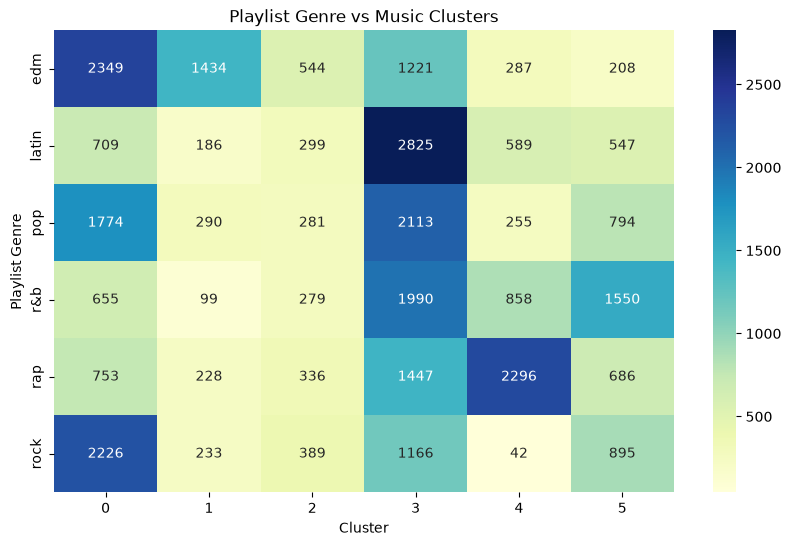

In [27]:
genre_cluster = pd.crosstab(
    df['playlist_genre'],
    df['Cluster']
)

print("Genre-wise Cluster Analysis:")
display(genre_cluster)

plt.figure(figsize=(10, 6))

sns.heatmap(
    genre_cluster,
    annot=True,
    fmt='d',
    cmap='YlGnBu'
)

plt.title("Playlist Genre vs Music Clusters")
plt.xlabel("Cluster")
plt.ylabel("Playlist Genre")
plt.show()

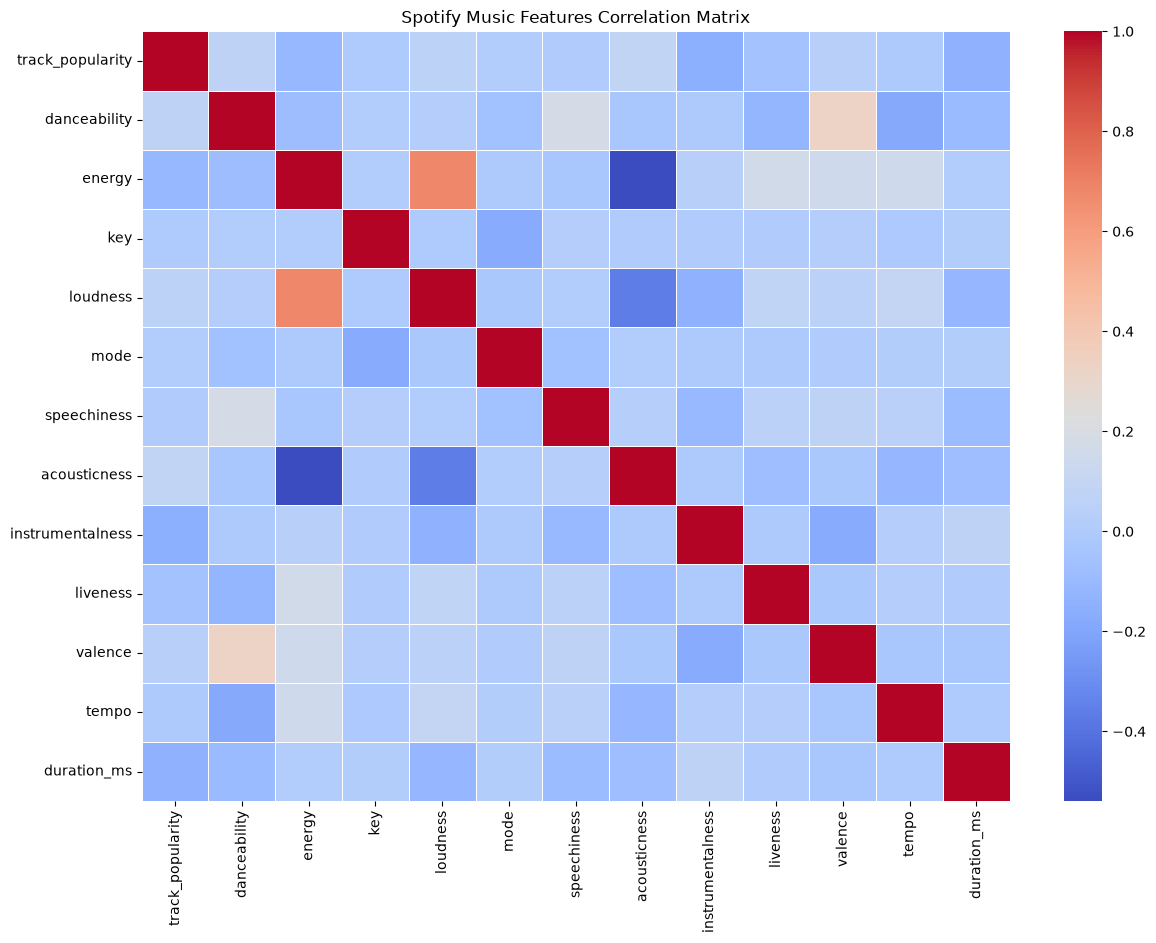

In [29]:
numeric_df = df.select_dtypes(include=np.number)
correlation = numeric_df.drop(
    columns=['Cluster'], errors='ignore'
).corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    cmap='coolwarm',
    annot=False,
    linewidths=0.5
)

plt.title("Spotify Music Features Correlation Matrix")
plt.show()

In [30]:
from sklearn.neighbors import NearestNeighbors

# Reset dataframe index
df = df.reset_index(drop=True)

# Train recommendation model
knn = NearestNeighbors(
    n_neighbors=6,
    metric='cosine',
    algorithm='brute'
)

knn.fit(X_scaled)

print("Song Recommendation Model Trained Successfully!")

# Recommendation function
def recommend_songs(song_name):

    matches = df[
        df['track_name'].str.lower() == song_name.lower()
    ]

    if matches.empty:
        print("Song not found!")
        return

    song_index = matches.index[0]

    distances, indices = knn.kneighbors(
        X_scaled[song_index].reshape(1, -1)
    )

    print("\nSelected Song:", song_name)
    print("\nRecommended Songs:\n")

    for i in indices[0][1:]:
        print(
            df.iloc[i]['track_name'],
            "-",
            df.iloc[i]['track_artist']
        )

Song Recommendation Model Trained Successfully!


In [31]:
recommend_songs("Memories")


Selected Song: Memories

Recommended Songs:

Memories - Maroon 5
Memories - Maroon 5
Memories - Maroon 5
Memories - Maroon 5
Memories - Maroon 5


In [32]:
playlist_analysis = df.groupby(
    'playlist_name'
).agg(
    Total_Songs=('track_name', 'count'),
    Average_Popularity=('track_popularity', 'mean')
).sort_values(
    by='Total_Songs',
    ascending=False
)

print("Top 10 Spotify Playlists:")
display(playlist_analysis.head(10))

Top 10 Spotify Playlists:


,Total_Songs,Average_Popularity
playlist_name,,
Indie Poptimism,308,42.555195
2020 Hits & 2019 Hits – Top Global Tracks 🔥🔥🔥,247,83.186235
Permanent Wave,244,54.348361
Hard Rock Workout,219,39.785388
Ultimate Indie Presents... Best Indie Tracks of the 2010s,198,59.797980
Fitness Workout Electro | House | Dance | Progressive House,195,11.892308
Southern Hip Hop,189,37.164021
Charts 2020 🔥Top 2020🔥Hits 2020🔥Summer 2020🔥Pop 2020🔥Popular Music🔥Clean Pop 2020🔥Sing Alongs,189,67.037037
"Classic Rock 70s 80s 90s, Rock Classics - 70s Rock, 80s Rock, 90s Rock Rock Classicos",182,30.120879


C:\Users\lenit\AppData\Local\Temp\ipykernel_17620\779601070.py:11: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\lenit\AppData\Local\Temp\ipykernel_17620\779601070.py:11: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()
C:\Users\lenit\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


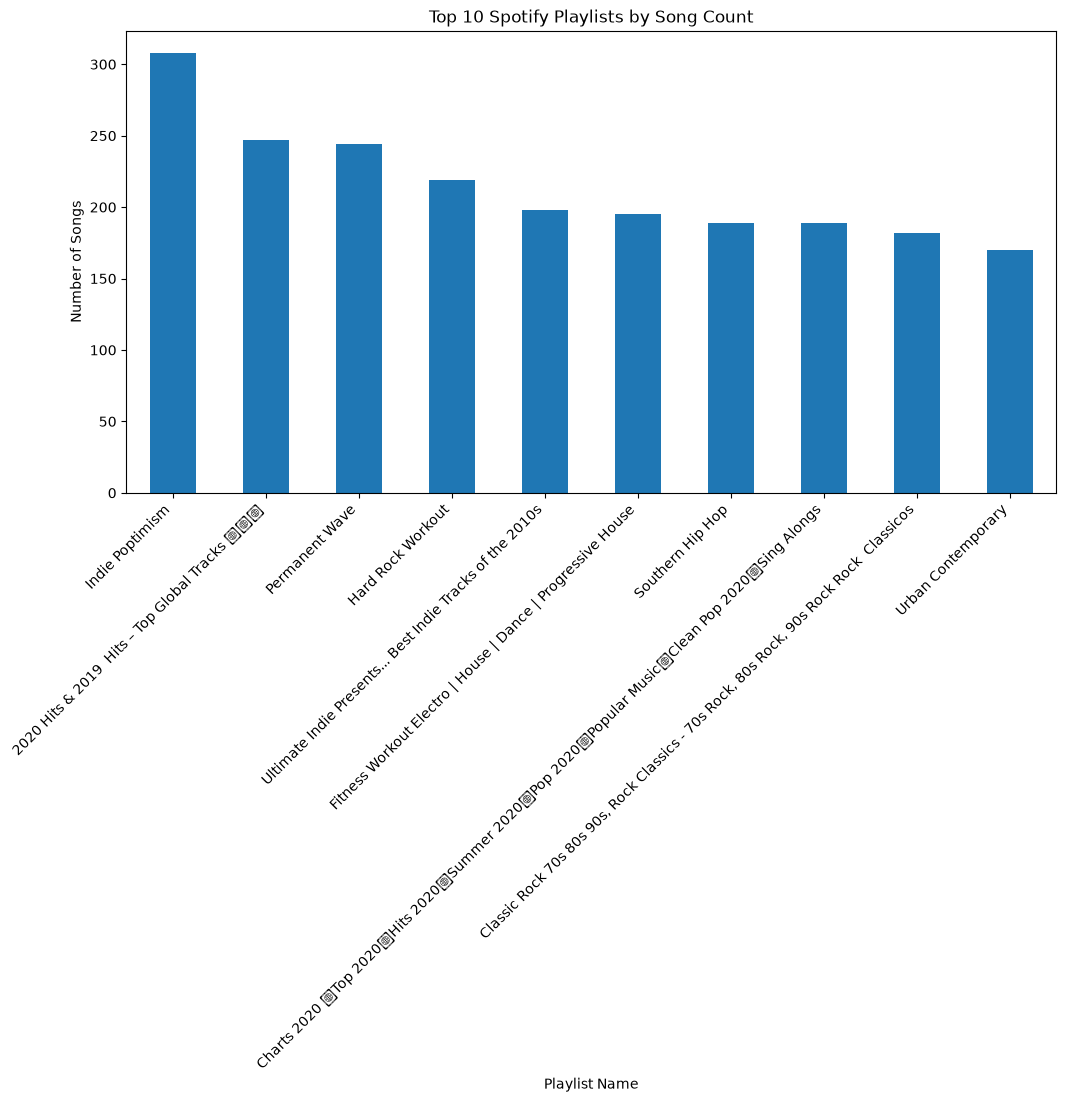

In [33]:
plt.figure(figsize=(12, 6))

playlist_analysis.head(10)['Total_Songs'].plot(
    kind='bar'
)

plt.title("Top 10 Spotify Playlists by Song Count")
plt.xlabel("Playlist Name")
plt.ylabel("Number of Songs")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [34]:
from sklearn.metrics import silhouette_score

score = silhouette_score(
    X_scaled,
    df['Cluster'],
    sample_size=3000,
    random_state=42
)

print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.1404
